# Audio ATCOSIM

Sumber: TU Graz / HF Jzuluaga variant. Subset 100 utterances dari satu speaker untuk smoke test fitur; tidak ada fatigue score.

In [1]:
from pathlib import Path
import os
for key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMBA_NUM_THREADS'):
    os.environ.setdefault(key, '4')
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
os.chdir(ROOT)
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from atc_fatigue.utils.runtime import load_config
config = load_config()
%matplotlib inline


In [2]:
manifest = pd.read_parquet('data/manifests/atcosim_subset.parquet')
features = pd.read_parquet('data/interim/atcosim_audio_features.parquet')
display(features[['sample_id', 'subject_id', 'duration_seconds', 'source_sample_rate', 'quality']].head())
print('Utterances:', len(features), 'Speakers:', features.subject_id.nunique())
print('eGeMAPS:', len(features.filter(regex='^egemaps__').columns), 'MFCC:', len(features.filter(regex='^mfcc_').columns))

,sample_id,subject_id,duration_seconds,source_sample_rate,quality
0,atcosim_sm1_01_001_000000_000329,sm1,3.299812,16000,ok
1,atcosim_sm1_01_002_000000_000466,sm1,4.660000,16000,ok
2,atcosim_sm1_01_003_000000_000422,sm1,4.229813,16000,ok
3,atcosim_sm1_01_004_000000_000264,sm1,2.640000,16000,ok
4,atcosim_sm1_01_005_000000_000391,sm1,3.910000,16000,ok


Utterances: 100 Speakers: 1
eGeMAPS: 88 MFCC: 26


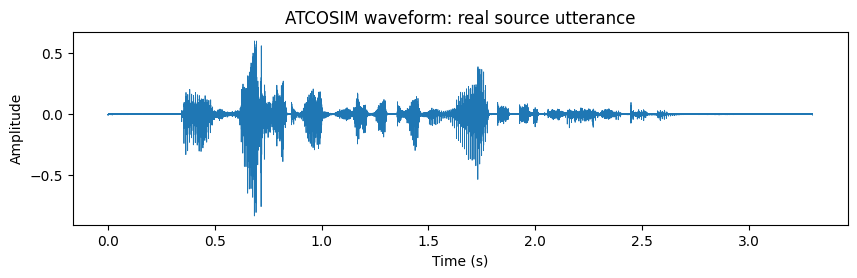

In [3]:
import soundfile as sf
signal, rate = sf.read(manifest.original_path.iloc[0])
fig, ax = plt.subplots(figsize=(10, 2.5))
ax.plot(np.arange(len(signal))/rate, signal, lw=0.6)
ax.set(xlabel='Time (s)', ylabel='Amplitude', title='ATCOSIM waveform: real source utterance')
plt.show()

In [4]:
from atc_fatigue.audio.features import extract_file, feature_names
rerun = extract_file(manifest.original_path.iloc[0], config['audio'])
assert len([k for k in rerun if k.startswith('egemaps__')]) == 88
display(pd.Series(rerun)[feature_names()[:6]])
display(features.filter(regex='^(egemaps__|mfcc_)').isna().mean().describe())

egemaps__F0semitoneFrom27.5Hz_sma3nz_amean             34.928963
egemaps__F0semitoneFrom27.5Hz_sma3nz_stddevNorm          0.25542
egemaps__F0semitoneFrom27.5Hz_sma3nz_percentile20.0    26.382868
egemaps__F0semitoneFrom27.5Hz_sma3nz_percentile50.0    31.587996
egemaps__F0semitoneFrom27.5Hz_sma3nz_percentile80.0    43.582027
egemaps__F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2       17.19916
dtype: object

count    114.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
dtype: float64

Durasi utterance bukan speech duration hasil VAD. Radio kompresi, noise, serta perbedaan microphone tetap menjadi risiko domain shift.